# UrbanHub · Partie 2 — Mobilité urbaine (CityBikes)

**Développeur 2** · Sources : `clean/citybikes/station_status` et `curated/citybikes/station_hourly`, produites par
`pipelines/streaming_citybikes/` à partir du collecteur (relevé toutes les 3 min, 9 villes).

| # | Question métier | Indicateur |
|---|---|---|
| 1 | Stations au plus fort taux d'utilisation | rotation = mouvements de vélos / capacité |
| 2 | Zones où l'offre est insuffisante | % du temps où les stations d'une zone sont vides |
| 3 | Pics d'utilisation journaliers | mouvements par heure de la journée (heure de Paris) |
| 4 | Déséquilibres géographiques | taux de remplissage selon la distance au centre |
| 5 | Stations critiques à rééquilibrer | stations vides (< 10 %) ou pleines (> 90 %) plus de 50 % du temps |

> **Mouvements de vélos** (`usage_events`) = somme des variations absolues de `bikes_available` entre deux relevés
> successifs (mesure commune du contrat). C'est une borne basse : un vélo pris puis rendu dans les 3 min est invisible.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "common").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from common import config

sns.set_theme(style="whitegrid")
FIG = ROOT / "docs" / "resultats" / "figures" / "mobilite"
FIG.mkdir(parents=True, exist_ok=True)
TZ = "Europe/Paris"

def lire(couche, chemin):
    return pd.read_parquet(config.lake_uri(couche, chemin))

st = lire("curated", "citybikes/station_hourly")
st["timestamp"] = pd.to_datetime(st["timestamp"]).dt.tz_localize("UTC")
st["heure_locale"] = st["timestamp"].dt.tz_convert(TZ)
st["heure"] = st["heure_locale"].dt.hour
for c in ("is_empty", "is_full"):                      # null quand la capacité est inconnue -> NaN
    st[c] = st[c].astype("float")
st["jour"] = np.where(st["heure_locale"].dt.dayofweek >= 5, "week-end", "semaine")

# Marseille : le flux renvoie 0 vélo dans toutes les stations (problème de la source, voir docs) -> exclue des analyses
st = st[st["city"] != "marseille"]

periode = f"{st.heure_locale.min():%d/%m/%Y %H:%M} → {st.heure_locale.max():%d/%m/%Y %H:%M} (heure de Paris)"
print("Période analysée :", periode)
print(f"{st.station_id.nunique():,} stations · {st.city.nunique()} villes · {len(st):,} lignes station × heure")
st.groupby("city").agg(stations=("station_id", "nunique"), heures=("timestamp", "nunique"),
                       mouvements=("usage_events", "sum")).sort_values("stations", ascending=False)

Période analysée : 18/11/2026 22:00 → 18/11/2026 22:00 (heure de Paris)
3,050 stations · 8 villes · 3,050 lignes station × heure


/var/folders/7c/h36nsrx568l4_r6ynq12hlfm0000gn/T/ipykernel_90222/2571488977.py:28: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  st["jour"] = np.where(st["heure_locale"].dt.dayofweek >= 5, "week-end", "semaine")


,stations,heures,mouvements
city,,,
paris,1522,1,0
lyon,458,1,0
toulouse,454,1,0
lille,267,1,11
bordeaux,221,1,0
montpellier,52,1,0
strasbourg,40,1,0
nantes,36,1,0


## Q1 · Quelles stations ont le plus fort taux d'utilisation ?

**Rotation** = mouvements de vélos par heure, rapportés à la capacité de la station (une petite station très active
compte autant qu'une grande). On ne garde que les stations observées au moins la moitié des heures.

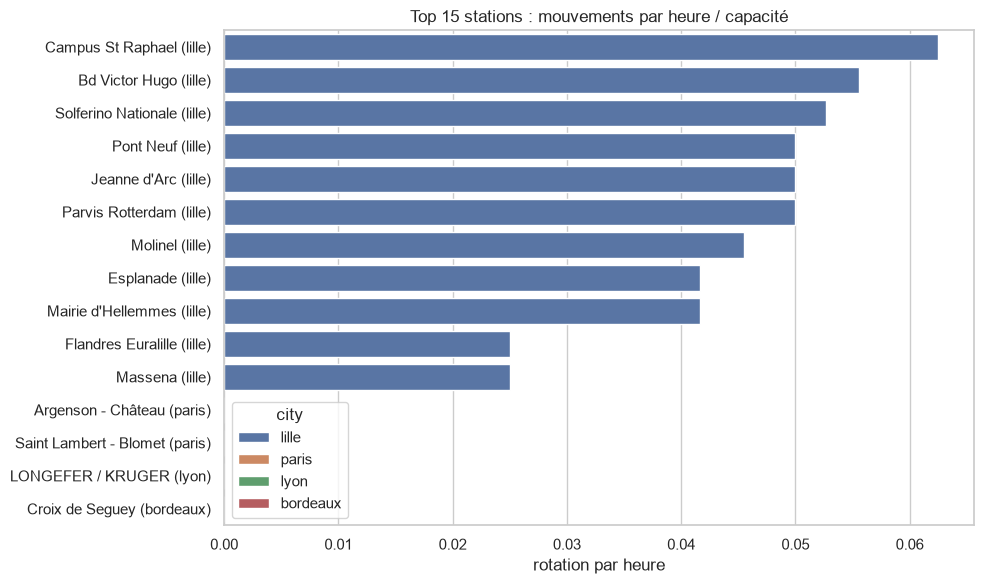

,city,station_name,capacite,mouvements_h,rotation_h
2909,lille,Campus St Raphael,16.0,1.0,0.062
1004,lille,Bd Victor Hugo,18.0,1.0,0.056
1038,lille,Solferino Nationale,19.0,1.0,0.053
396,lille,Pont Neuf,20.0,1.0,0.050
634,lille,Jeanne d'Arc,20.0,1.0,0.050
761,lille,Parvis Rotterdam,20.0,1.0,0.050
2019,lille,Molinel,22.0,1.0,0.045
372,lille,Esplanade,24.0,1.0,0.042
1222,lille,Mairie d'Hellemmes,24.0,1.0,0.042
302,lille,Flandres Euralille,40.0,1.0,0.025


In [2]:
par_station = st.groupby(["station_id", "station_name", "city"]).agg(
    mouvements=("usage_events", "sum"), heures=("timestamp", "nunique"), capacite=("capacity", "median"),
    lat=("latitude", "first"), lon=("longitude", "first")).reset_index()
par_station = par_station[(par_station.capacite > 0) & (par_station.heures >= 0.5 * st.timestamp.nunique())]
par_station["mouvements_h"] = par_station.mouvements / par_station.heures
par_station["rotation_h"] = par_station.mouvements_h / par_station.capacite

top = par_station.nlargest(15, "rotation_h")
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top, y=top.station_name + " (" + top.city + ")", x="rotation_h", hue="city", dodge=False, ax=ax)
ax.set(title="Top 15 stations : mouvements par heure / capacité", xlabel="rotation par heure", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "q1_top_stations.png", dpi=120); plt.show()
top[["city", "station_name", "capacite", "mouvements_h", "rotation_h"]].round(3)

## Q2 · Zones où l'offre de vélos est insuffisante

On découpe chaque ville en carreaux d'environ 1 km. Une zone est **sous-équipée** quand ses stations sont souvent
vides (< 10 % de vélos) : les usagers y trouvent rarement un vélo.

In [3]:
CARREAU = 0.01   # ~1,1 km en latitude, ~0,75 km en longitude
z = st.assign(zone_lat=(st.latitude / CARREAU).round() * CARREAU, zone_lon=(st.longitude / CARREAU).round() * CARREAU)
zones = z.groupby(["city", "zone_lat", "zone_lon"]).agg(
    stations=("station_id", "nunique"), pct_vide=("is_empty", "mean"),
    velos_moyens=("bikes_available", "mean")).reset_index()
zones = zones[zones.stations >= 2]
zones["pct_vide"] = (zones.pct_vide * 100).round(1)

print("Zones les plus souvent vides (au moins 2 stations) :")
display(zones.nlargest(12, "pct_vide"))

villes = zones.groupby("city").apply(lambda g: (g.pct_vide >= 50).mean() * 100, include_groups=False).rename("% zones vides > 50 % du temps")
villes.sort_values(ascending=False).round(1).to_frame()

Zones les plus souvent vides (au moins 2 stations) :


,city,zone_lat,zone_lon,stations,pct_vide,velos_moyens
11,bordeaux,44.80,-0.60,2,100.0,0.500000
34,bordeaux,44.83,-0.60,3,100.0,0.666667
180,lille,50.68,3.17,4,100.0,0.500000
184,lille,50.69,3.16,2,100.0,0.000000
237,lyon,45.74,4.84,4,100.0,0.250000
242,lyon,45.74,4.89,5,100.0,0.000000
257,lyon,45.75,4.90,2,100.0,0.000000
267,lyon,45.76,4.86,12,100.0,0.500000
305,lyon,45.79,4.80,2,100.0,0.500000
332,montpellier,43.60,3.89,2,100.0,0.500000


,% zones vides > 50 % du temps
city,
strasbourg,50.0
montpellier,44.4
lyon,28.0
toulouse,18.9
lille,15.9
bordeaux,14.0
paris,12.3
nantes,0.0


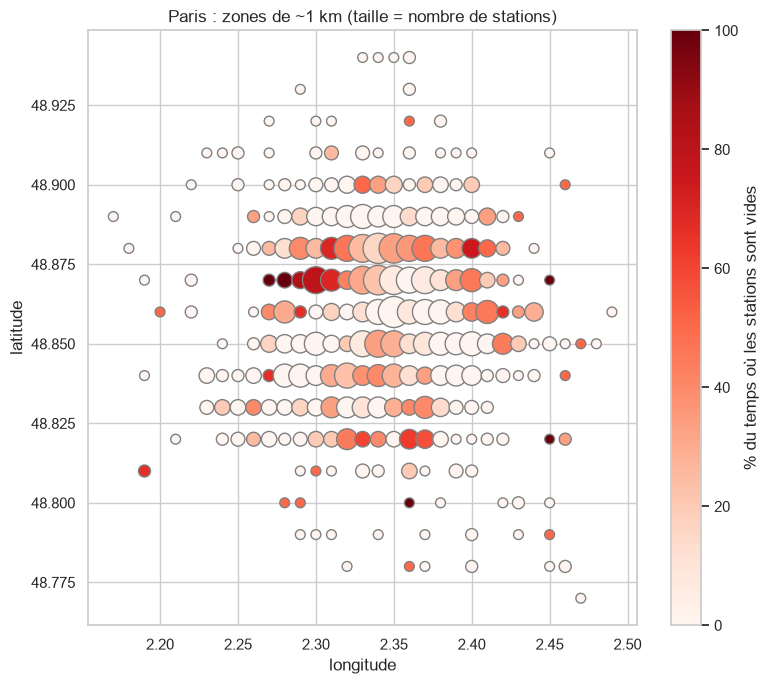

In [4]:
paris = zones[zones.city == "paris"]
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(paris.zone_lon, paris.zone_lat, c=paris.pct_vide, s=paris.stations * 25, cmap="Reds", vmin=0, vmax=100, edgecolor="grey")
plt.colorbar(sc, label="% du temps où les stations sont vides")
ax.set(title="Paris : zones de ~1 km (taille = nombre de stations)", xlabel="longitude", ylabel="latitude")
plt.tight_layout(); plt.savefig(FIG / "q2_zones_paris.png", dpi=120); plt.show()

## Q3 · Pics d'utilisation journaliers

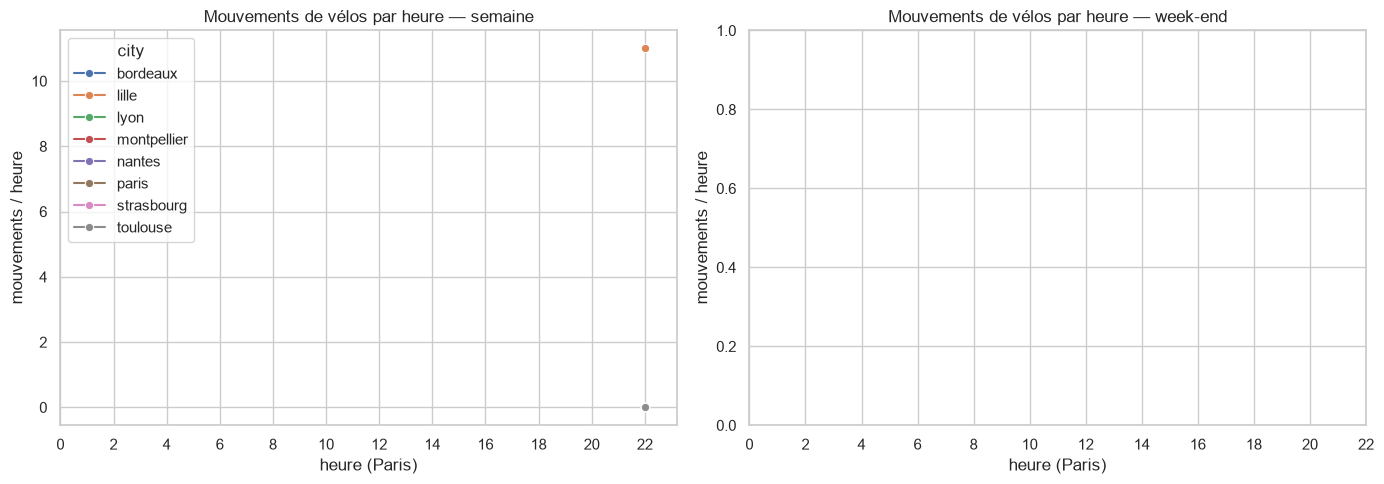

,city,jour,heure du pic,mouvements
0,bordeaux,semaine,22,0.0
1,lille,semaine,22,11.0
2,lyon,semaine,22,0.0
3,montpellier,semaine,22,0.0
4,nantes,semaine,22,0.0
5,paris,semaine,22,0.0
6,strasbourg,semaine,22,0.0
7,toulouse,semaine,22,0.0


In [5]:
profil = (st.groupby(["city", "jour", "heure", st.heure_locale.dt.date])["usage_events"].sum()
            .groupby(["city", "jour", "heure"]).mean().reset_index(name="mouvements"))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, j in zip(axes, ["semaine", "week-end"]):
    sns.lineplot(data=profil[profil.jour == j], x="heure", y="mouvements", hue="city", marker="o", ax=ax)
    ax.set(title=f"Mouvements de vélos par heure — {j}", xlabel="heure (Paris)", ylabel="mouvements / heure", xticks=range(0, 24, 2))
plt.tight_layout(); plt.savefig(FIG / "q3_pics_journaliers.png", dpi=120); plt.show()

pics = profil.loc[profil.groupby(["city", "jour"]).mouvements.idxmax(), ["city", "jour", "heure", "mouvements"]]
pics.rename(columns={"heure": "heure du pic"}).round(0)

## Q4 · Déséquilibres géographiques de la disponibilité

Taux de remplissage moyen des stations selon leur **distance au centre-ville**. Un écart fort centre / périphérie
signale des flux pendulaires : les vélos s'accumulent d'un côté et manquent de l'autre.

anneau,< 2 km,2-5 km,5-10 km,> 10 km,écart-type entre stations (pts)
city,,,,,
bordeaux,30.7,45.0,37.0,NaN,28.1
lille,32.9,47.1,25.9,25.9,28.0
lyon,36.9,39.4,44.4,36.9,33.0
montpellier,16.9,15.4,15.7,NaN,15.5
nantes,43.6,60.0,NaN,NaN,25.6
paris,58.2,32.1,44.9,48.7,30.7
strasbourg,36.9,35.9,47.7,45.0,22.0
toulouse,28.6,51.1,41.4,37.5,32.8


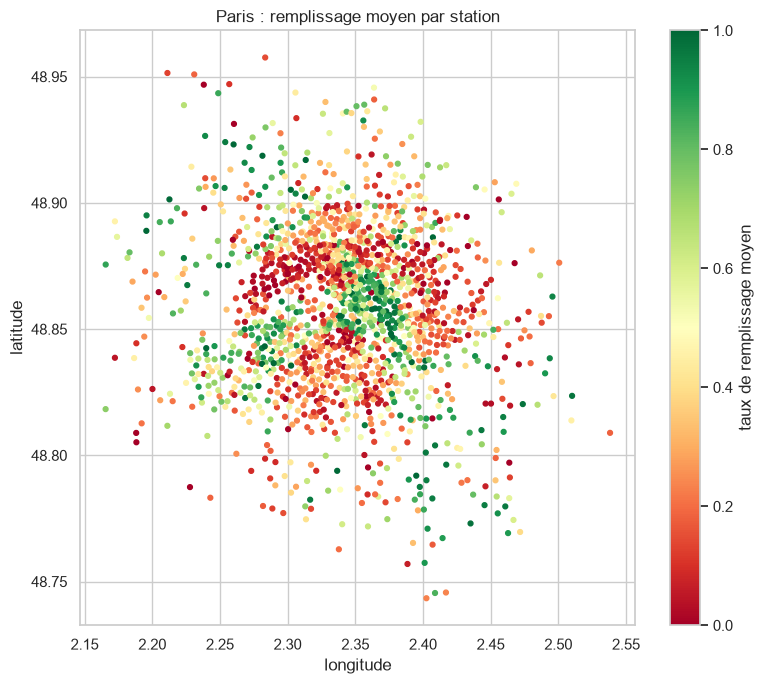

In [6]:
from pipelines.streaming_citybikes.city import CITIES

def km(lat1, lon1, lat2, lon2):
    p = np.radians
    a = np.sin(p(lat2 - lat1) / 2) ** 2 + np.cos(p(lat1)) * np.cos(p(lat2)) * np.sin(p(lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

occ = st.groupby(["station_id", "city"]).agg(lat=("latitude", "first"), lon=("longitude", "first"),
                                             remplissage=("occupancy_rate", "mean")).reset_index().dropna()
occ["dist_km"] = [km(a, b, *CITIES[c]) for a, b, c in zip(occ.lat, occ.lon, occ.city)]
occ["anneau"] = pd.cut(occ.dist_km, [0, 2, 5, 10, 30], labels=["< 2 km", "2-5 km", "5-10 km", "> 10 km"])

tab = occ.pivot_table(index="city", columns="anneau", values="remplissage", aggfunc="mean", observed=False).mul(100).round(1)
tab["écart-type entre stations (pts)"] = occ.groupby("city").remplissage.std().mul(100).round(1)
display(tab)

fig, ax = plt.subplots(figsize=(8, 7))
p = occ[occ.city == "paris"]
sc = ax.scatter(p.lon, p.lat, c=p.remplissage, cmap="RdYlGn", vmin=0, vmax=1, s=12)
plt.colorbar(sc, label="taux de remplissage moyen")
ax.set(title="Paris : remplissage moyen par station", xlabel="longitude", ylabel="latitude")
plt.tight_layout(); plt.savefig(FIG / "q4_desequilibre_paris.png", dpi=120); plt.show()

## Q5 · Stations critiques à rééquilibrer

Une station est **critique** quand elle est **vide** (< 10 % de vélos : on ne peut plus emprunter) ou **pleine**
(> 90 % : on ne peut plus rendre) pendant **plus de 50 %** des heures observées.

In [7]:
crit = st.groupby(["station_id", "station_name", "city"]).agg(
    pct_vide=("is_empty", "mean"), pct_pleine=("is_full", "mean"), capacite=("capacity", "median")).reset_index()
crit = crit[crit.capacite > 0]
crit["statut"] = np.select([crit.pct_vide > 0.5, crit.pct_pleine > 0.5], ["à remplir (souvent vide)", "à vider (souvent pleine)"], "ok")

resume = crit.groupby(["city", "statut"]).size().unstack(fill_value=0)
resume["% critiques"] = (100 * (1 - resume.get("ok", 0) / resume.sum(axis=1))).round(1)
display(resume.sort_values("% critiques", ascending=False))

liste = crit[crit.statut != "ok"].assign(pct_vide=lambda d: (d.pct_vide * 100).round(0), pct_pleine=lambda d: (d.pct_pleine * 100).round(0))
liste.sort_values(["pct_vide", "pct_pleine"], ascending=False).head(20)

statut,ok,à remplir (souvent vide),à vider (souvent pleine),% critiques
city,,,,
lyon,279,119,58,38.8
toulouse,301,100,53,33.7
montpellier,32,16,0,33.3
paris,1111,272,134,26.8
lille,196,52,18,26.3
bordeaux,171,41,9,22.6
nantes,30,4,2,16.7
strasbourg,37,3,0,7.5


,station_id,station_name,city,pct_vide,pct_pleine,capacite,statut
8,00718dcc2fa34b019d9cba625c94b1e7,Mouton Duvernet - Général Leclerc,paris,100.0,0.0,28.0,à remplir (souvent vide)
10,009f50f6bcfd618daa5fbda53ce14ccd,Piscine Judaique,bordeaux,100.0,0.0,27.0,à remplir (souvent vide)
14,011948af9fad35dfda6e1adf45b81bed,Belleville - Télégraphe,paris,100.0,0.0,41.0,à remplir (souvent vide)
20,014cb48626b158d02eb81447060df5fd,Miromesnil - La Boétie,paris,100.0,0.0,34.0,à remplir (souvent vide)
25,01dc3bd2df858fa39bd07b94b95bf41c,00125 - BARRIERE DE PARIS MÉTRO,toulouse,100.0,0.0,21.0,à remplir (souvent vide)
26,01ff513b035661b763345664322c461e,Saint-Augustin,paris,100.0,0.0,41.0,à remplir (souvent vide)
30,025f7801fffbe71a3578ac52150fccce,SUBSISTANCES,lyon,100.0,0.0,22.0,à remplir (souvent vide)
33,02a0cf65598bcf0ada8d9fe1a114b550,CREPS,bordeaux,100.0,0.0,1.0,à remplir (souvent vide)
46,0390b2ea485d0642446d8bcb38826f43,Universite Catholique,lille,100.0,0.0,31.0,à remplir (souvent vide)
58,049b9c927f1d9fe0e0aa71d22d672656,Tage - Italie,paris,100.0,0.0,31.0,à remplir (souvent vide)


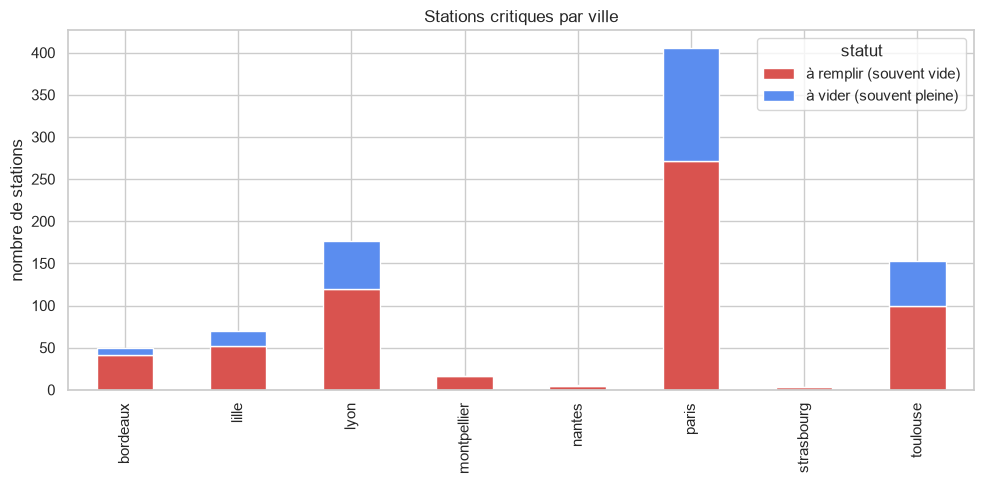

In [8]:
ax = resume.drop(columns="% critiques").drop(columns="ok", errors="ignore").plot.bar(stacked=True, figsize=(10, 5), color=["#d9534f", "#5b8def"])
ax.set(title="Stations critiques par ville", ylabel="nombre de stations", xlabel="")
plt.tight_layout(); plt.savefig(FIG / "q5_stations_critiques.png", dpi=120); plt.show()

## Limites

- Les résultats dépendent de la durée de collecte : il faut **au moins 2 semaines** pour comparer semaine / week-end
  et lisser la météo. Relancer ce notebook après `clean` + `curate`.
- `usage_events` sous-estime l'usage réel (mouvements compensés entre deux relevés de 3 min).
- **Nice** n'a pas de réseau à stations dans CityBikes ; **Marseille** renvoie 0 vélo partout (problème de la source) : exclues.